# Blok 2 · Część 2 — Lepsze dane

**Uczenie maszynowe w Pythonie** — Politechnika Gdańska, 2026

W części 1 nauczyliśmy się **rzetelnie oceniać** model. Teraz używamy tego narzędzia, żeby sprawdzić, co naprawdę poprawia dane — a co tylko wygląda na poprawę.

**Plan:**
1. Braki danych — skąd się biorą i czym je uzupełniać
2. Wartości odstające — jak je wykryć i co z nimi zrobić
3. Kodowanie zmiennych kategorycznych — w tym pułapka leakage
4. Selekcja cech — kiedy pomaga, a kiedy oszukuje

**Dane:** znane z Zajęć 1 — rezerwacje hoteli (klasyfikacja) i California Housing (regresja). Model: wciąż tylko liniowy (ostatni raz :)).

**Zasada na cały notebook:** każdą decyzję sprawdzamy **przez CV na tych samych foldach** i patrzymy na dwie rzeczy: **jak duża** jest różnica i **w ilu foldach** wariant wygrał. Bez tego nie odróżnimy poprawy od szumu (część 1).

## 0. Przygotowanie

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (8, 5)
sns.set_theme(style="whitegrid")
print("scikit-learn", sklearn.__version__)   # kurs wymaga >= 1.4 (TargetEncoder jest dostępny od 1.3)
SKLEARN_1_8 = tuple(int(x) for x in sklearn.__version__.split(".")[:2]) >= (1, 8)   # potrzebne w sekcji 4

scikit-learn 1.9.1


In [25]:
URL = "https://raw.githubusercontent.com/ml-course-pg/ml-course-pg-2026/main/01-wprowadzenie/data/"

def wczytaj(nazwa):
    try:
        return pd.read_csv(f"../01-wprowadzenie/data/{nazwa}")
    except FileNotFoundError:
        return pd.read_csv(URL + nazwa)

hotele = wczytaj("hotels.csv")
kalifornia = wczytaj("california_housing.csv")
print("hotele:    ", hotele.shape)
print("kalifornia:", kalifornia.shape)

hotele:     (10000, 28)
kalifornia: (20433, 9)


Dwa narzędzia, których użyjemy w każdej sekcji:

* **`RepeatedStratifiedKFold` / `RepeatedKFold`** — CV z części 1, powtórzone 3 razy z różnym tasowaniem (5 foldów × 3 = 15 wyników). Przy małych różnicach to daje stabilniejszą ocenę.
* **`porownaj_warianty`** — liczy CV dla kilku wariantów na **tych samych foldach** i pokazuje: średni wynik, **średnią różnicę** względem wariantu bazowego, **odchylenie standardowe tej różnicy** oraz **w ilu z 15 foldów wariant był lepszy**.

**Jak czytać tabelę — pewność to nie to samo co wielkość:**

* **„lepszy w foldach”** mówi o **pewności**. 15/15 — różnica na pewno nie jest przypadkiem. Około 7/15 — rzut monetą.
* **„różnica vs pierwszy”** mówi o **wielkości**. Wariant może wygrać 15/15 o 0.001 AUC — wynik pewny, ale praktycznie bez znaczenia. Decyzję podejmujemy, patrząc na **obie** liczby (i na koszt: czas obliczeń, złożoność, łatwość wyjaśnienia).
* **„odch. std różnicy”** — różnice liczymy fold po foldzie (*porównanie sparowane*), więc to, że jeden fold jest „trudny” dla wszystkich wariantów, się skraca. Jeśli średnia różnica jest kilka razy większa od jej odchylenia, wynik jest stabilny.

In [26]:
from sklearn.model_selection import RepeatedStratifiedKFold, RepeatedKFold, cross_val_score

cv_klas = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
cv_reg = RepeatedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

def porownaj_warianty(warianty, cv, scoring):
    # warianty: {nazwa: (model, X, y)}; pierwszy wariant = punkt odniesienia
    # metryki "neg_..." (np. RMSE) odwracamy znakiem — wtedy mniejszy wynik = lepszy
    wyniki = {n: cross_val_score(m, X_, y_, cv=cv, scoring=scoring) for n, (m, X_, y_) in warianty.items()}
    wiekszy_lepszy = not scoring.startswith("neg_")
    if not wiekszy_lepszy:
        wyniki = {n: -w for n, w in wyniki.items()}
    baza = next(iter(wyniki.values()))
    wiersze = []
    for i, (n, w) in enumerate(wyniki.items()):
        roznica = w - baza                      # różnica fold po foldzie (te same foldy!)
        lepszy = (roznica > 0) if wiekszy_lepszy else (roznica < 0)
        wiersze.append({"wariant": n, "średnia": w.mean(), "odch. std": w.std(),
                        "różnica vs pierwszy": roznica.mean(), "odch. std różnicy": roznica.std(),
                        "lepszy w foldach": "—" if i == 0 else f"{lepszy.sum()}/{len(w)}"})
    return pd.DataFrame(wiersze).set_index("wariant").round(4)

Pipeline dla hoteli — ten sam co w części 1 (rozwiązanie z Zajęć 1), ale z „pokrętłami”, którymi będziemy kręcić: imputer dla liczb, sposób kodowania kolumn `country` i `agent`, opcjonalna selekcja cech i opcjonalne dodatkowe kolumny.

W części numerycznej najpierw jest `log1p`, a dopiero potem imputacja — dzięki temu kolumna „tu był brak” (wskaźnik braku, sekcja 1) trafia do modelu jako czyste 0/1, a nie jako zlogarytmowana liczba.

In [27]:
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression

CECHY_NUM = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights",
             "adults", "children", "babies", "is_repeated_guest",
             "previous_cancellations", "previous_bookings_not_canceled",
             "days_in_waiting_list", "adr",
             "required_car_parking_spaces", "total_of_special_requests"]
CECHY_KAT = ["hotel", "meal", "market_segment", "distribution_channel",
             "reserved_room_type", "deposit_type", "customer_type"]
CECHY_WIELE = ["country", "agent"]          # kategorie o wielu wartościach

def kodowanie_onehot_rzadkie():
    return OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10)

def zbuduj_model(imputer_num=None, kodowanie_wiele="onehot_rzadkie", selekcja=None, dodatkowe=None):
    # dodatkowe: lista trójek (nazwa, transformer, kolumny) doklejana do ColumnTransformera
    imputer_num = imputer_num if imputer_num is not None else SimpleImputer(strategy="median")
    czesci = [
        ("numeryczne", Pipeline([
            ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
            ("imputacja", imputer_num),
            ("skalowanie", StandardScaler()),
        ]), CECHY_NUM),
        ("kategoryczne", Pipeline([
            ("imputacja", SimpleImputer(strategy="most_frequent")),
            ("kodowanie", OneHotEncoder(handle_unknown="ignore")),
        ]), CECHY_KAT),
    ]
    if kodowanie_wiele is not None:
        enc = kodowanie_onehot_rzadkie() if kodowanie_wiele == "onehot_rzadkie" else kodowanie_wiele
        czesci.append(("wiele_wartosci", enc, CECHY_WIELE))
    if dodatkowe:
        czesci += dodatkowe
    kroki = [("preprocessing", ColumnTransformer(czesci))]
    if selekcja is not None:
        kroki.append(("selekcja", selekcja))
    kroki.append(("klasyfikator", LogisticRegression(max_iter=2000)))
    return Pipeline(kroki)

# country i agent jako tekst; brak = osobna kategoria "brak" (rezerwacja bez agenta to informacja, nie dziura)
hotele_X = hotele.drop(columns="is_canceled").copy()
hotele_X["agent"] = hotele_X["agent"].astype("Int64").astype(str).replace("<NA>", "brak")
hotele_X["country"] = hotele_X["country"].fillna("brak")
hotele_y = hotele["is_canceled"]

---
## 1. Braki danych

### 1.1 Najpierw pytanie: **dlaczego** brakuje?

Trzy mechanizmy (nazwy z literatury — warto je znać):

| mechanizm | znaczenie | przykład | konsekwencja |
|---|---|---|---|
| **MCAR** (*missing completely at random*) | brak zupełnie losowy | ankieter zgubił kartkę | brak nie niesie informacji; tracimy tylko część danych |
| **MAR** (*missing at random*) | brak zależy od **innych, widocznych** cech | starsze domy częściej nie mają podanego dochodu | brak da się „wytłumaczyć” widocznymi cechami |
| **MNAR** (*missing not at random*) | brak zależy od **samej brakującej wartości** | osoby o wysokich dochodach częściej nie podają dochodu | **sam fakt braku jest informacją**, a proste uzupełnianie jest obciążone |

Osobny przypadek, który łatwo pomylić z MNAR: brak zależy od **targetu** (np. system gubi dane głównie w rezerwacjach, które potem anulowano). To nie jest czwarty mechanizm, tylko **sygnał ostrzegawczy** — wrócimy do niego w punkcie 1.5.

Spójrzmy na prawdziwe braki w hotelach:

In [28]:
braki = hotele.isna().mean().sort_values(ascending=False)
braki[braki > 0].to_frame("odsetek braków").round(4)

,odsetek braków
company,0.9430
agent,0.1359
country,0.0044
children,0.0001


* **`company` — 94% braków.** To nie są „zgubione dane”: brak oznacza, że rezerwacji **nie zrobiła firma**. Imputacja „najczęstszą firmą” byłaby nonsensem.
* **`agent` — ok. 14% braków.** Brak = rezerwacja **bez pośrednika** (bezpośrednio w hotelu). Dlatego w pipeline traktujemy go jako osobną kategorię `"brak"`.
* `country`, `children` — pojedyncze braki, praktycznie bez znaczenia.

### 1.2 Eksperyment: ta sama kolumna, trzy mechanizmy

California Housing. Usuwamy część wartości **najważniejszej cechy** — dochodu (`MedInc`) — na trzy sposoby:

* **MCAR** — każda wartość ma tę samą szansę zniknąć (30%),
* **MAR** — w starszych dzielnicach (`HouseAge > 30`) brak zdarza się 5× częściej (50% vs 10%). Brak zależy od widocznej cechy, a nie od dochodu,
* **MNAR** — w dzielnicach o dochodzie **powyżej mediany** brak zdarza się 5× częściej (50% vs 10%). Brak zależy od **samego dochodu**, którego w tych wierszach nie widzimy.

In [29]:
kalifornia["BedrmsShare"] = kalifornia["AveBedrms"] / kalifornia["AveRooms"]   # cecha z Zajęć 1
X_kal = kalifornia.drop(columns="MedHouseVal")
y_kal = kalifornia["MedHouseVal"]

def usun_medinc(p_braku):
    rng = np.random.default_rng(0)
    X_ = X_kal.copy()
    X_.loc[rng.random(len(X_kal)) < p_braku, "MedInc"] = np.nan
    return X_

X_kal_mcar = usun_medinc(np.full(len(X_kal), 0.3))
X_kal_mar = usun_medinc(np.where(X_kal["HouseAge"] > 30, 0.5, 0.1))
X_kal_mnar = usun_medinc(np.where(X_kal["MedInc"] > X_kal["MedInc"].median(), 0.5, 0.1))

pd.DataFrame({
    nazwa: {"odsetek braków": X_["MedInc"].isna().mean(),
            "śr. cena tam, gdzie brak": y_kal[X_["MedInc"].isna()].mean(),
            "śr. cena tam, gdzie jest": y_kal[X_["MedInc"].notna()].mean()}
    for nazwa, X_ in [("MCAR", X_kal_mcar), ("MAR", X_kal_mar), ("MNAR", X_kal_mnar)]
}).T.round(3)

,odsetek braków,"śr. cena tam, gdzie brak","śr. cena tam, gdzie jest"
MCAR,0.292,2.071,2.068
MAR,0.282,2.123,2.047
MNAR,0.299,2.472,1.897


Ostatnie dwie kolumny to pierwsza wskazówka. Przy MCAR średnia cena tam, gdzie jest brak, i tam, gdzie go nie ma, jest praktycznie taka sama. Przy MAR różnica jest niewielka (starsze dzielnice są nieco droższe). Przy MNAR dzielnice z brakiem są **wyraźnie droższe** (2.47 vs 1.90) — **sam brak mówi coś o cenie**.

Dla każdego mechanizmu porównujemy te same strategie. Model: zwykła regresja liniowa, metryka RMSE (im mniej, tym lepiej). Punkt odniesienia — **mediana**, czyli to, co robiliśmy dotąd.

* **wskaźnik braku** (`add_indicator=True`) — imputer dokleja kolumnę 0/1 „tu był brak”,
* `KNNImputer` uzupełnia brak średnią z *k* najbardziej podobnych dzielnic. Podobieństwo to odległość liczona po wszystkich kolumnach, więc **przed nim musi być skalowanie** — bez niego dominowałaby kolumna o największych liczbach (`Population`, tysiące osób), a różnice w położeniu czy dochodzie prawie by się nie liczyły,
* `IterativeImputer` traktuje uzupełnianie jak predykcję: dla każdej kolumny z brakami uczy regresję na pozostałych kolumnach i nią przewiduje brakujące wartości (gdy braki są w kilku kolumnach, powtarza to w kilku rundach). W sklearn jest oznaczony jako eksperymentalny, stąd dodatkowy import.

In [30]:
from sklearn.linear_model import LinearRegression
from sklearn.impute import KNNImputer
from sklearn.experimental import enable_iterative_imputer   # noqa: F401 — „włącza” IterativeImputer
from sklearn.impute import IterativeImputer

def regresja(imputer):
    return make_pipeline(imputer, StandardScaler(), LinearRegression())

def regresja_knn(k=10, wskaznik=False):
    # KNN liczy odległości, więc skalowanie stoi PRZED imputerem (w pozostałych wariantach — po nim)
    return make_pipeline(StandardScaler(), KNNImputer(n_neighbors=k, add_indicator=wskaznik), LinearRegression())

def warianty_imputacji(X_braki):
    return {
        "mediana": (regresja(SimpleImputer(strategy="median")), X_braki, y_kal),
        "mediana + wskaźnik braku": (regresja(SimpleImputer(strategy="median", add_indicator=True)), X_braki, y_kal),
        "KNN (k=10, po skalowaniu)": (regresja_knn(), X_braki, y_kal),
        "Iterative": (regresja(IterativeImputer(random_state=0)), X_braki, y_kal),
    }

ODNIESIENIE = {"[odniesienie] dane bez braków": (regresja(SimpleImputer()), X_kal, y_kal)}

### 1.3 MCAR i MAR: brak, który nic nie mówi o cenie

Pokazujemy na MAR — MCAR daje praktycznie ten sam obraz. Oprócz czterech strategii dokładamy dwa warianty: **usunięcie całej kolumny** `MedInc` oraz KNN, który szuka sąsiadów **tylko po położeniu** (`Latitude`, `Longitude`) — żeby sprawdzić, skąd KNN bierze swoją przewagę.

In [48]:
knn_po_polozeniu = ColumnTransformer(
    [("knn", make_pipeline(StandardScaler(), KNNImputer(n_neighbors=10)), ["MedInc", "Latitude", "Longitude"])],
    remainder=StandardScaler())

warianty_mar = warianty_imputacji(X_kal_mar) | {
    "usunięcie kolumny MedInc": (make_pipeline(StandardScaler(), LinearRegression()), X_kal_mar.drop(columns="MedInc"), y_kal),
    "KNN tylko po położeniu": (make_pipeline(knn_po_polozeniu, LinearRegression()), X_kal_mar, y_kal),
} | ODNIESIENIE
porownaj_warianty(warianty_mar, cv_reg, "neg_root_mean_squared_error")

,średnia,odch. std,różnica vs pierwszy,odch. std różnicy,lepszy w foldach
wariant,,,,,
mediana,0.8218,0.0168,0.0000,0.0000,—
mediana + wskaźnik braku,0.8217,0.0167,-0.0001,0.0002,11/15
"KNN (k=10, po skalowaniu)",0.7507,0.0115,-0.0712,0.0088,15/15
Iterative,0.7874,0.0235,-0.0344,0.0120,15/15
usunięcie kolumny MedInc,0.8977,0.0299,0.0759,0.0140,0/15
KNN tylko po położeniu,0.7404,0.0132,-0.0814,0.0113,15/15
[odniesienie] dane bez braków,0.7197,0.0114,-0.1022,0.0117,15/15


RMSE w setkach tys. USD, ujemna różnica = lepiej.

* **KNN i Iterative wygrywają we wszystkich foldach**, a **usunięcie kolumny** jest wyraźnie gorsze. Imputer wielowymiarowy pomaga zawsze wtedy, gdy brakującą wartość da się przewidzieć z innych cech — niezależnie od tego, *dlaczego* zniknęła. Dlatego przy MCAR wynik jest taki sam.
* **„KNN tylko po położeniu”**: sąsiedzi szukani **wyłącznie po współrzędnych** dają nawet lepszy wynik (0.740) niż po wszystkich cechach (0.751). Dochód zależy przede wszystkim od **sąsiedztwa geograficznego** — a KNN szuka właśnie „sąsiadów”. Pozostałe cechy w mierze odległości tylko rozmywają to podobieństwo.
* **Wskaźnik braku nic nie daje** — różnica 0.0001 przy 11/15 foldów to niewiele ponad rzut monetą.
* Nikt nie dochodzi do „danych bez braków” (sufit). Czym więc MAR różni się od MCAR? Tym, **czy proste metody są obciążone** (przy MAR mediana z obserwowanych wartości pochodzi głównie z młodszych dzielnic) — a nie tym, czy imputer wielowymiarowy pomaga.

❓ **Skoro KNN jest tak dobry, czemu nie używać go zawsze?**

**Odpowiedź:**
1. jest **wolny** — dla każdego braku szuka sąsiadów w całym zbiorze treningowym, co przy setkach tysięcy wierszy boli,
2. wymaga **skalowania i sensownej miary podobieństwa** — przy wielu kolumnach kategorycznych „sąsiedzi” stają się przypadkowi,
3. pomaga tylko wtedy, gdy brakującą wartość **da się przewidzieć z innych cech** (tu tak: dochód zależy od położenia). Dla cechy niezwiązanej z resztą zgaduje niewiele lepiej niż mediana.

### 1.4 MNAR: brak zależy od samej brakującej wartości

Teraz dochodu brakuje głównie w **bogatszych** dzielnicach. Dokładamy wariant KNN **ze wskaźnikiem braku**.

In [32]:
warianty_mnar = warianty_imputacji(X_kal_mnar) | {
    "KNN + wskaźnik braku": (regresja_knn(wskaznik=True), X_kal_mnar, y_kal),
} | ODNIESIENIE
porownaj_warianty(warianty_mnar, cv_reg, "neg_root_mean_squared_error")

,średnia,odch. std,różnica vs pierwszy,odch. std różnicy,lepszy w foldach
wariant,,,,,
mediana,0.8463,0.0220,0.0000,0.0000,—
mediana + wskaźnik braku,0.8145,0.0153,-0.0318,0.0073,15/15
"KNN (k=10, po skalowaniu)",0.7568,0.0128,-0.0895,0.0139,15/15
Iterative,0.7844,0.0151,-0.0619,0.0150,15/15
KNN + wskaźnik braku,0.7525,0.0116,-0.0938,0.0150,15/15
[odniesienie] dane bez braków,0.7197,0.0114,-0.1267,0.0160,15/15


* **Wskaźnik braku nagle pomaga**: przy MAR dawał 0.0001, tu obniża RMSE o ok. 0.03 we wszystkich foldach. Brak oznacza teraz „dochód raczej wysoki” — a to informacja o cenie.
* **Imputery wielowymiarowe nadal pomagają najbardziej**, bo dochód wciąż da się w dużej części odtworzyć z sąsiedztwa. Ale są **obciążone**: uczą się z wierszy, w których dochód jest, a te są przy MNAR przeciętnie biedniejsze — więc braki uzupełniają systematycznie za nisko (mediana — jeszcze mocniej).
* **Najlepsze jest połączenie: KNN + wskaźnik braku** (0.7525): imputer odtwarza wartość, a wskaźnik pozwala modelowi skorygować obciążenie. To przepis na MNAR.
* Nikt nie dochodzi do „danych bez braków”, a strata względem tego sufitu jest większa niż przy MAR — przy MNAR część informacji naprawdę zniknęła.

### 1.5 Uwaga: brak powiązany z targetem → podejrzenie leakage

Ostatni scenariusz wygląda podobnie do MNAR, ale jest czymś innym. Hotele: usuwamy wartości `lead_time` (ile dni przed przyjazdem zrobiono rezerwację), ale **częściej w rezerwacjach, które potem zostały anulowane** (50% vs 10%). Wyobraźmy sobie system, w którym część danych „ginie” w procesie obsługi anulowania. Brak zależy tu od **targetu**, a nie od samej wartości `lead_time`.

In [33]:
rng = np.random.default_rng(0)
p_braku = np.where(hotele_y == 1, 0.5, 0.1)
hotele_X_brak_y = hotele_X.copy()
hotele_X_brak_y.loc[rng.random(len(hotele_X)) < p_braku, "lead_time"] = np.nan

print(f"braki w lead_time: {hotele_X_brak_y['lead_time'].isna().mean():.1%}")
print("odsetek anulowań:  wśród braków", f"{hotele_y[hotele_X_brak_y['lead_time'].isna()].mean():.1%}",
      "  wśród pozostałych", f"{hotele_y[hotele_X_brak_y['lead_time'].notna()].mean():.1%}")

braki w lead_time: 25.0%
odsetek anulowań:  wśród braków 74.8%   wśród pozostałych 24.5%


In [34]:
warianty_brak_y = {
    "mediana": (zbuduj_model(SimpleImputer(strategy="median")), hotele_X_brak_y, hotele_y),
    "mediana + wskaźnik braku": (zbuduj_model(SimpleImputer(strategy="median", add_indicator=True)), hotele_X_brak_y, hotele_y),
    "[odniesienie] dane bez braków": (zbuduj_model(), hotele_X, hotele_y),
}
porownaj_warianty(warianty_brak_y, cv_klas, "roc_auc")

,średnia,odch. std,różnica vs pierwszy,odch. std różnicy,lepszy w foldach
wariant,,,,,
mediana,0.9073,0.0053,0.0000,0.0000,—
mediana + wskaźnik braku,0.9316,0.0037,0.0242,0.0039,15/15
[odniesienie] dane bez braków,0.9093,0.0056,0.0019,0.0016,15/15


* **Wskaźnik braku daje skok ROC-AUC i przebija dane bez braków** (0.932 vs 0.909). Uczciwa cecha nie może dać więcej, niż dają kompletne dane — wskaźnik przemyca informację o **targecie**: „brak `lead_time`” znaczy tu „rezerwacja raczej anulowana”.
* W prawdziwym projekcie taki wynik to **alarm**, a nie sukces. Pytanie kontrolne: skąd bierze się brak i czy będzie znany **w momencie predykcji**? Jeśli `lead_time` znika dopiero w procesie anulowania, to w chwili rezerwacji brak jeszcze nie istnieje — model świetny w CV zawiedzie na produkcji. To leakage, nie cecha.

**Podsumowanie sekcji 1:**

| mechanizm | prosta imputacja (mediana) | imputer wielowymiarowy (KNN, Iterative) | wskaźnik braku |
|---|---|---|---|
| MCAR | nieobciążona, ale traci informację | pomaga, jeśli wartość da się przewidzieć z innych cech | praktycznie nic |
| MAR | może być obciążona | pomaga (j.w.) i usuwa obciążenie, bo uwzględnia cechy, od których zależy brak | praktycznie nic |
| MNAR | obciążona | pomaga, ale też jest obciążony | **wyraźnie pomaga** — najlepiej razem z imputerem wielowymiarowym |
| brak zależny od targetu | — | — | „pomaga” podejrzanie dobrze → **sprawdź leakage** |

W praktyce nie wiemy na pewno, który mechanizm działa — dlatego porównujemy warianty w CV. Najprostsza opcja, **usunięcie wierszy** z brakami, jest dopuszczalna tylko przy MCAR i niewielkiej liczbie braków; w pozostałych przypadkach zniekształca dane.

---
## 2. Wartości odstające

### 2.1 Wykrywanie

Na Zajęciach 1 zauważyliśmy dziwne wartości w California, ale ich nie ruszaliśmy. Wracamy do nich.

In [35]:
X_kal.describe().T[["min", "25%", "50%", "75%", "max"]].round(2)

,min,25%,50%,75%,max
MedInc,0.50,2.56,3.54,4.74,15.00
HouseAge,1.00,18.00,29.00,37.00,52.00
AveRooms,0.85,4.44,5.23,6.05,141.91
AveBedrms,0.33,1.01,1.05,1.10,34.07
Population,3.00,787.00,1166.00,1722.00,35682.00
AveOccup,0.69,2.43,2.82,3.28,1243.33
Latitude,32.54,33.93,34.26,37.72,41.95
Longitude,-124.35,-121.80,-118.49,-118.01,-114.31
BedrmsShare,0.10,0.18,0.20,0.24,1.00


`AveOccup` (średnia liczba osób na gospodarstwo) ma maksimum **ponad 1 200**, a `AveRooms` — **ponad 140 pokoi** średnio na mieszkanie. Trzy popularne sposoby wykrywania:

* **reguła IQR** — odstająca, gdy wartość leży dalej niż 1.5 × IQR od pierwszego/trzeciego kwartyla (to samo, co „wąsy” na boxplocie),
* **z-score** — odstająca, gdy |x − średnia| / odch. std > 3. Słabość: średnia i odchylenie same są „ciągnięte” przez outliery, więc reguła może je przeoczyć,
* **reguła domenowa** — wiedza o świecie: 1 200 osób w jednym gospodarstwie to nie rodzina, tylko np. akademik, więzienie albo błąd danych.

In [36]:
def odstajace_iqr(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    return (s < q1 - k * (q3 - q1)) | (s > q3 + k * (q3 - q1))

def odstajace_z(s, prog=3):
    return ((s - s.mean()) / s.std()).abs() > prog

kolumny = ["AveRooms", "AveBedrms", "Population", "AveOccup"]
pd.DataFrame({
    "IQR (1.5)": {c: odstajace_iqr(X_kal[c]).mean() for c in kolumny},
    "z-score > 3": {c: odstajace_z(X_kal[c]).mean() for c in kolumny},
}).round(4).rename_axis("odsetek wierszy uznanych za odstające")

,IQR (1.5),z-score > 3
odsetek wierszy uznanych za odstające,,
AveRooms,0.0249,0.0065
AveBedrms,0.0692,0.0071
Population,0.0582,0.0166
AveOccup,0.0347,0.0004


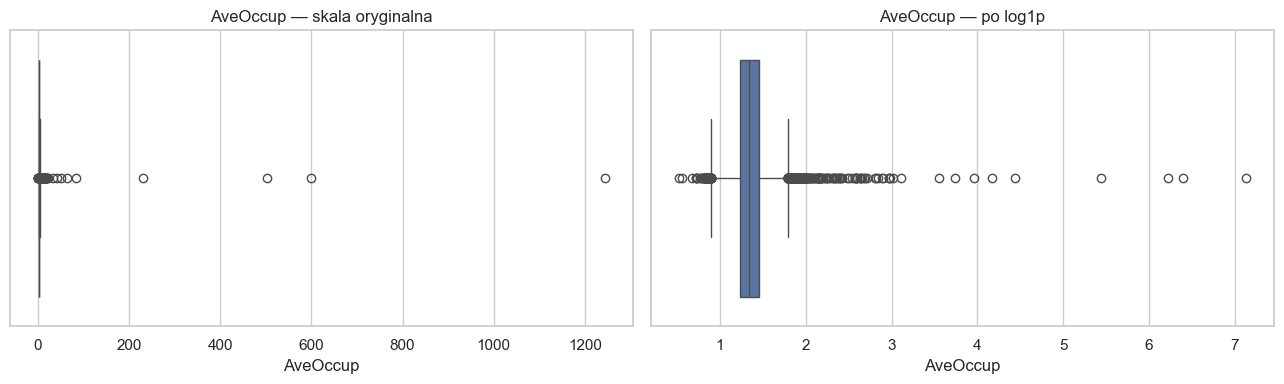

Dzielnice z AveOccup > 20:


,AveOccup,Population,AveRooms,HouseAge,MedInc
3338,599.7,4198.0,5.1,36.0,5.5
5924,21.3,2688.0,4.5,52.0,1.9
8784,41.2,1154.0,7.3,52.0,9.3
9080,83.2,8733.0,5.1,5.0,4.2
11986,63.8,1275.0,7.6,8.0,1.6
12912,230.2,6675.0,8.3,52.0,6.1
13240,34.0,2886.0,5.3,36.0,4.3
16261,51.4,1542.0,5.4,26.0,5.7
16510,502.5,6532.0,9.1,46.0,4.3
18825,1243.3,7460.0,3.2,45.0,10.2


In [37]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(x=X_kal["AveOccup"], ax=ax[0]); ax[0].set_title("AveOccup — skala oryginalna")
sns.boxplot(x=np.log1p(X_kal["AveOccup"]), ax=ax[1]); ax[1].set_title("AveOccup — po log1p")
plt.tight_layout(); plt.show()

print("Dzielnice z AveOccup > 20:")
X_kal.loc[X_kal["AveOccup"] > 20, ["AveOccup", "Population", "AveRooms", "HouseAge", "MedInc"]].round(1)

Dwie metody dają **bardzo różne** odsetki — reguła IQR przy skośnych rozkładach oznacza jako „odstające” sporo zwykłych, dużych dzielnic, a z-score łapie tylko skrajności. Nie ma jednej poprawnej odpowiedzi: wykrywanie to **diagnoza**, a decyzję podejmujemy po zrozumieniu danych.

Dzielnice z `AveOccup > 20` mają po kilka tysięcy mieszkańców, ale **bardzo mało gospodarstw domowych** — to najpewniej obiekty zbiorowe (akademiki, koszary, więzienia, domy opieki) albo błędy spisu. Nie są to „zwykłe” dzielnice, więc nie powinny wyginać modelu dla całej reszty. **Najpierw zrozumieć, potem działać.**

### 2.2 Ucięty target — to nie jest outlier

Zanim zaczniemy przycinać, jeszcze jedna osobliwość California Housing — tym razem w **targecie**.

MedHouseVal = 5.00001 (maksimum): 4.7% dzielnic
HouseAge = 52 (maksimum):        6.2% dzielnic


/var/folders/rp/bmdm1pzn5mz7sg8nbg4981p00000gn/T/ipykernel_6070/2456753468.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  srednia_ceny = y_kal.groupby(pd.cut(X_kal["MedInc"], [0, 2, 4, 6, 8, 10, 12, 16])).mean()


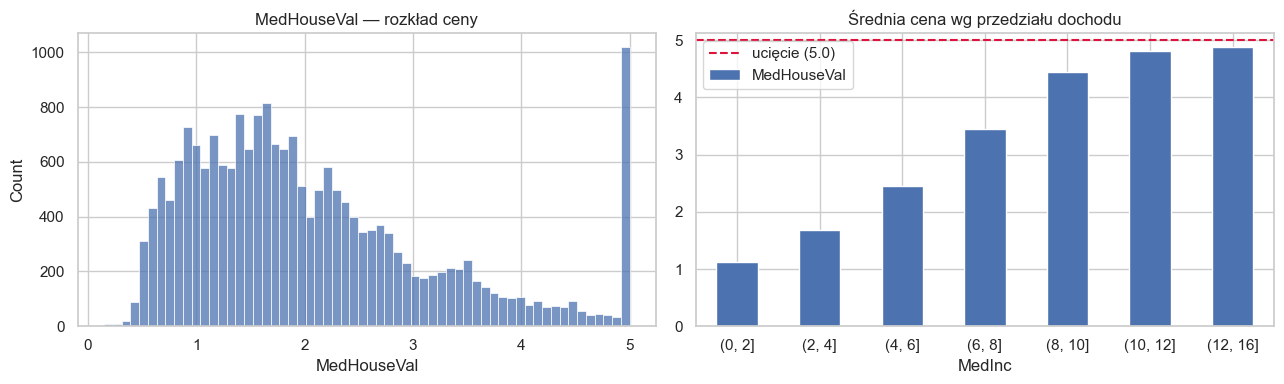

In [38]:
print(f"MedHouseVal = {y_kal.max():.5f} (maksimum): {(y_kal == y_kal.max()).mean():.1%} dzielnic")
print(f"HouseAge = {X_kal['HouseAge'].max():.0f} (maksimum):        {(X_kal['HouseAge'] == X_kal['HouseAge'].max()).mean():.1%} dzielnic")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(y_kal, bins=60, ax=ax[0]); ax[0].set_title("MedHouseVal — rozkład ceny")
srednia_ceny = y_kal.groupby(pd.cut(X_kal["MedInc"], [0, 2, 4, 6, 8, 10, 12, 16])).mean()
srednia_ceny.plot(kind="bar", ax=ax[1], rot=0)
ax[1].axhline(5, color="crimson", ls="--", label="ucięcie (5.0)")
ax[1].set_title("Średnia cena wg przedziału dochodu"); ax[1].set_xlabel("MedInc"); ax[1].legend()
plt.tight_layout(); plt.show()

Co można zrobić:
* **zostawić** i pamiętać o tym przy interpretacji błędów (tak robimy tutaj),
* **usunąć** ucięte wiersze — ale wtedy model nic nie wie o najdroższych dzielnicach, a w praktyce one się zdarzą.

Za chwilę zobaczymy, że to ucięcie wpływa na wyniki winsoryzacji.

### 2.3 Strategie: co z outlierami zrobić?

| strategia | co robi | uwagi |
|---|---|---|
| nic | — | punkt odniesienia |
| **winsoryzacja** | przycina wartości do kwantyli (np. 1% i 99%) | progi liczymy **na treningu** → własny transformer |
| **log1p** | „ściąga” długi ogon | znane z Zajęć 1 |
| usunięcie wierszy | — | tylko z treningu i tylko gdy to błąd |

Winsoryzację musimy napisać sami — ale to tylko kilka linijek. Zasada ta sama co w każdym transformerze: progi uczone w `fit` (na treningu), stosowane w `transform`:

In [39]:
from sklearn.base import BaseEstimator, TransformerMixin

class Winsoryzacja(BaseEstimator, TransformerMixin):
    # przycina każdą kolumnę do kwantyli [q, 1-q] wyznaczonych na danych treningowych
    def __init__(self, q=0.01):
        self.q = q

    def fit(self, X, y=None):
        A = np.asarray(X, dtype=float)
        self.dolne_ = np.nanquantile(A, self.q, axis=0)
        self.gorne_ = np.nanquantile(A, 1 - self.q, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.dolne_, self.gorne_)

In [40]:
skosne = ["AveRooms", "AveBedrms", "Population", "AveOccup"]

def tylko(kolumny, transformer):
    # stosuje transformer tylko do wskazanych kolumn, pozostałe przepuszcza bez zmian
    return ColumnTransformer([("wybrane", transformer, kolumny)], remainder="passthrough")

def ols(*przed):
    return make_pipeline(*przed, StandardScaler(), LinearRegression())

warianty_out = {
    "nic": (ols(), X_kal, y_kal),
    "winsoryzacja 1% — 4 kolumny skośne": (ols(tylko(skosne, Winsoryzacja(0.01))), X_kal, y_kal),
    "winsoryzacja 1% — skośne + MedInc": (ols(tylko(skosne + ["MedInc"], Winsoryzacja(0.01))), X_kal, y_kal),
    "winsoryzacja 1% — wszystkie kolumny": (ols(Winsoryzacja(0.01)), X_kal, y_kal),
    "log1p cech skośnych": (ols(tylko(skosne, FunctionTransformer(np.log1p))), X_kal, y_kal),
}
porownaj_warianty(warianty_out, cv_reg, "neg_root_mean_squared_error")

,średnia,odch. std,różnica vs pierwszy,odch. std różnicy,lepszy w foldach
wariant,,,,,
nic,0.7197,0.0114,0.0000,0.0000,—
winsoryzacja 1% — 4 kolumny skośne,0.6674,0.0102,-0.0523,0.0059,15/15
winsoryzacja 1% — skośne + MedInc,0.6549,0.0096,-0.0648,0.0049,15/15
winsoryzacja 1% — wszystkie kolumny,0.6505,0.0094,-0.0692,0.0048,15/15
log1p cech skośnych,0.6734,0.0126,-0.0463,0.0061,15/15


Trzy lekcje:

1. **Winsoryzacja i log1p działają** — we wszystkich foldach. Już samo przycięcie 4 kolumn skośnych obniża RMSE z 0.720 do 0.667: kilka skrajnych dzielnic „wyginało” prostą regresji dla wszystkich pozostałych.
2. **Winsoryzacja wszystkich kolumn jest jeszcze lepsza (0.651) — ale nie dlatego, że usuwa więcej outlierów.** Większość dodatkowego zysku daje jedna kolumna: `MedInc` (wiersz „skośne + MedInc”: 0.655). `MedInc` nie ma absurdalnych wartości — przycięcie pomaga z powodu **uciętego targetu** (2.2): w najbogatszych dzielnicach cena prawie przestaje rosnąć, a prosta rośnie dalej. Przycięcie dochodu na 99. percentylu „spłaszcza” prostą tam, gdzie spłaszcza się cena.
   Lekcja: **sprawdzaj, z której kolumny pochodzi zysk.** „Winsoryzacja wszystkiego działa” to nie to samo co „usunęliśmy outliery”.
3. **log1p** jest odrobinę słabszy od winsoryzacji tych samych kolumn (0.673 vs 0.667), ale nie wymaga wybierania progu i zachowuje kolejność wartości — oba podejścia są rozsądne.

### 2.4 Most do Zajęć 1: skąd się wzięła „katastrofa”?

Na Zajęciach 1 regresja na **cechach wielomianowych stopnia 2** bez regularyzacji dała RMSE ≈ 10 — 9× gorzej niż baseline. Wytłumaczyliśmy to „za dużą liczbą cech”. Sprawdźmy, co się stanie, gdy przed wielomianami przytniemy outliery:

In [41]:
from sklearn.preprocessing import PolynomialFeatures

def wielomiany(*przed):
    return make_pipeline(*przed, StandardScaler(), PolynomialFeatures(degree=2, include_bias=False), StandardScaler(), LinearRegression())

for nazwa, m in [("wielomiany st. 2, bez winsoryzacji", wielomiany()),
                 ("wielomiany st. 2, z winsoryzacją 1%", wielomiany(Winsoryzacja(0.01)))]:
    w = -cross_val_score(m, X_kal, y_kal, cv=cv_reg, scoring="neg_root_mean_squared_error")
    print(f"{nazwa:<40} RMSE: mediana foldów {np.median(w):.3f}   średnia {w.mean():.3f}   najgorszy fold {w.max():.2f}")

wielomiany st. 2, bez winsoryzacji       RMSE: mediana foldów 0.687   średnia 2.666   najgorszy fold 21.21
wielomiany st. 2, z winsoryzacją 1%      RMSE: mediana foldów 0.598   średnia 0.597   najgorszy fold 0.61


Bez winsoryzacji: w typowym foldzie wynik jest przyzwoity, ale w niektórych foldach model **wybucha** — wystarczy, że w teście trafi się dzielnica z ekstremalną wartością, którą wielomian podnosi do kwadratu.

Czyli: „katastrofę” z Zajęć 1 powodowały głównie **outliery**, a nie sama liczba cech. Regularyzacja ją ukryła, ale nie usunęła przyczyny. Dobra lekcja: **zanim sięgniesz po mocniejszy model albo karę — obejrzyj dane.**

❓ **Dlaczego progi winsoryzacji liczymy na treningu, a nie na całych danych?**

**Odpowiedź:** bo kwantyle to parametry „wyuczone” z danych — dokładnie jak średnia w `StandardScaler`. Liczenie ich na całym zbiorze to data leakage: progi „widziałyby” zbiór walidacyjny. Dlatego `Winsoryzacja` jest transformerem z `fit`/`transform` i siedzi w pipeline.

---
## 3. Kodowanie zmiennych kategorycznych

Wracamy do hoteli. Dwie kolumny mają **bardzo dużo wartości**: `country` i `agent` (ID biura podróży).

In [42]:
print("liczba różnych wartości:", {c: hotele_X[c].nunique() for c in CECHY_WIELE})
hotele_X["agent"].value_counts().head(8)

liczba różnych wartości: {'country': 99, 'agent': 225}


agent
9       2715
brak    1359
240     1156
1        584
14       317
7        276
6        275
250      247
Name: count, dtype: int64

### 3.1 Porównanie sposobów kodowania

Porównujemy pięć sposobów potraktowania tych dwóch kolumn (reszta pipeline'u bez zmian):

* **bez nich** — punkt odniesienia: ile te kolumny w ogóle są warte?
* **OneHot (wszystkie wartości)** — jedna kolumna 0/1 na każdy kraj i każdego agenta (ponad 300 kolumn),
* **OneHot + `min_frequency=10`** — rzadkie wartości łączymy w jedną kategorię „infrequent” (rozwiązanie z Zajęć 1),
* **`OrdinalEncoder`** — każda wartość dostaje numer (0, 1, 2, …) — **celowo zły** pomysł: agent nr 240 nie jest „większy” od agenta nr 9,
* **`TargetEncoder`** — każda wartość zastąpiona **średnim odsetkiem anulowań** dla tej wartości (z wygładzaniem rzadkich).

In [43]:
from sklearn.preprocessing import OrdinalEncoder, TargetEncoder
import warnings
warnings.filterwarnings("ignore", message=".*TargetEncoder.shuffle.*", category=FutureWarning)

warianty_kod = {
    "OneHot + min_frequency=10": (zbuduj_model(), hotele_X, hotele_y),
    "bez country i agent": (zbuduj_model(kodowanie_wiele=None), hotele_X, hotele_y),
    "OneHot (wszystkie wartości)": (zbuduj_model(kodowanie_wiele=OneHotEncoder(handle_unknown="ignore")), hotele_X, hotele_y),
    "OrdinalEncoder (numery)": (zbuduj_model(kodowanie_wiele=make_pipeline(
        OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), StandardScaler())), hotele_X, hotele_y),
    "TargetEncoder": (zbuduj_model(kodowanie_wiele=make_pipeline(
        TargetEncoder(random_state=0), StandardScaler())), hotele_X, hotele_y),
}
porownaj_warianty(warianty_kod, cv_klas, "roc_auc")

,średnia,odch. std,różnica vs pierwszy,odch. std różnicy,lepszy w foldach
wariant,,,,,
OneHot + min_frequency=10,0.9093,0.0056,0.0000,0.0000,—
bez country i agent,0.8634,0.0059,-0.0458,0.0047,0/15
OneHot (wszystkie wartości),0.9100,0.0054,0.0008,0.0004,14/15
OrdinalEncoder (numery),0.8769,0.0053,-0.0323,0.0043,0/15
TargetEncoder,0.8999,0.0063,-0.0094,0.0029,0/15


* **`country` i `agent` są bardzo cenne** — bez nich ROC-AUC spada o ok. 0.046, we wszystkich foldach.
* **Pełny OneHot vs OneHot z łączeniem rzadkich:** pełny wygrywa w 14/15 foldach, ale tylko o 0.0008 AUC — przy wyraźnie większej liczbie kolumn. Wynik **pewny, ale praktycznie bez znaczenia** — klasyczny przypadek „pewność ≠ wielkość”. Zostajemy przy prostszym wariancie.
* **`OrdinalEncoder` traci większość tej wartości** — model liniowy dostaje jedną liczbę i musi założyć, że „agent nr 240” jest „pomiędzy” agentem 239 a 241. To nie ma sensu dla ID. (`OrdinalEncoder` jest dobry tylko dla kategorii z **naturalnym porządkiem**: S < M < L, „podstawowe < średnie < wyższe”.)
* **`TargetEncoder` jest tu nieco gorszy od OneHot.** To uczciwy wynik: zamienia setki kolumn na jedną liczbę na kolumnę — wygodne, ale model liniowy traci elastyczność. `TargetEncoder` błyszczy przy **tysiącach** kategorii (np. kody pocztowe, ID produktów).

### 3.2 Pułapka: kodowanie targetem bez pipeline'u

`TargetEncoder` liczy średnią targetu dla każdej kategorii — czyli **uczy się z `y`**. Co się stanie, jeśli zrobimy to „ręcznie” na całym zbiorze, przed CV? Żeby efekt był wyraźny, dodajmy do danych kolumnę **czystego szumu**: losowe „ID polecającego” z 2 000 możliwych wartości. Ta kolumna **nie ma żadnego związku** z anulowaniem.

In [44]:
rng = np.random.default_rng(1)
hotele_X_id = hotele_X.copy()
hotele_X_id["id_polecajacego"] = rng.integers(0, 2000, len(hotele_X)).astype(str)

# ŹLE: średnia targetu policzona na CAŁYCH danych, potem CV
srednie = hotele_y.groupby(hotele_X_id["id_polecajacego"]).mean()
hotele_X_id["id_polecajacego_srednia_ZLE"] = hotele_X_id["id_polecajacego"].map(srednie)
model_zle = zbuduj_model(dodatkowe=[("id_zle", "passthrough", ["id_polecajacego_srednia_ZLE"])])

# DOBRZE: TargetEncoder w pipeline (cross-fitting wewnątrz każdego foldu)
model_dobrze = zbuduj_model(dodatkowe=[
    ("id_dobrze", make_pipeline(TargetEncoder(random_state=0), StandardScaler()), ["id_polecajacego"])])

porownaj_warianty({
    "bez kolumny ID": (zbuduj_model(), hotele_X_id, hotele_y),
    "ID: średnia targetu na całych danych (ŹLE)": (model_zle, hotele_X_id, hotele_y),
    "ID: TargetEncoder w pipeline (DOBRZE)": (model_dobrze, hotele_X_id, hotele_y),
}, cv_klas, "roc_auc")

,średnia,odch. std,różnica vs pierwszy,odch. std różnicy,lepszy w foldach
wariant,,,,,
bez kolumny ID,0.9093,0.0056,0.0000,0.0000,—
ID: średnia targetu na całych danych (ŹLE),0.9374,0.0036,0.0281,0.0038,15/15
ID: TargetEncoder w pipeline (DOBRZE),0.9093,0.0055,-0.0000,0.0001,6/15


Kolumna, która jest **czystym szumem**, „poprawia” wynik we wszystkich foldach, gdy zakodujemy ją targetem przed CV. Dlaczego? Przy 2 000 wartości każde ID ma tylko kilka rezerwacji, więc średnia anulowań dla ID to w praktyce **podpowiedź, jaki jest target tego wiersza** — model ją wykorzystuje także w walidacji.

---
## 4. Selekcja cech

Po co wybierać cechy? Mniej szumu i przeuczenia, szybszy model, łatwiejsze wyjaśnienie biznesowi. Trzy rodziny metod:

| rodzina | jak działa | przykłady w sklearn | wada |
|---|---|---|---|
| **filtry** | ocenia każdą cechę osobno | `VarianceThreshold`, `SelectKBest` | nie widzi, że cechy razem mogą być ważne |
| **wrappery** | trenuje model na różnych podzbiorach | `RFE`, `RFECV`, `SequentialFeatureSelector` | drogie obliczeniowo |
| **embedded** | selekcja „przy okazji” treningu | L1 / Lasso → `SelectFromModel` | zależy od siły kary |

### 4.1 Pułapka: selekcja poza pipeline'em

Najpierw najważniejsza lekcja. Tworzymy dane, w których **nie ma żadnego sygnału**: 500 obserwacji, 2 000 kolumn losowego szumu, losowy target 0/1. Uczciwy model powinien mieć accuracy ≈ 50%.

In [45]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import StratifiedKFold

rng = np.random.default_rng(0)
X_szum = pd.DataFrame(rng.normal(size=(500, 2000)))
y_szum = pd.Series(rng.integers(0, 2, 500))
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# ŹLE: wybieramy 20 „najlepszych” cech na CAŁYCH danych, potem CV
wybrane = SelectKBest(f_classif, k=20).fit(X_szum, y_szum).get_support()
acc_zle = cross_val_score(LogisticRegression(max_iter=1000), X_szum.loc[:, wybrane], y_szum, cv=cv5)

# DOBRZE: selekcja jako krok pipeline'u — w każdym foldzie od nowa
acc_dobrze = cross_val_score(make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000)),
                             X_szum, y_szum, cv=cv5)

print(f"selekcja przed CV (ŹLE):    accuracy = {acc_zle.mean():.3f}")
print(f"selekcja w pipeline (DOBRZE): accuracy = {acc_dobrze.mean():.3f}")

selekcja przed CV (ŹLE):    accuracy = 0.680
selekcja w pipeline (DOBRZE): accuracy = 0.468


### 4.2 Selekcja na hotelach

Po OneHot pipeline hoteli produkuje ponad 160 kolumn. Czy da się je przerzedzić bez straty jakości?

In [46]:
from sklearn.feature_selection import VarianceThreshold, SelectFromModel

def logreg_l1(C):
    # od scikit-learn 1.8 rodzaj kary wybiera się przez l1_ratio (parametr penalty jest wycofywany)
    if SKLEARN_1_8:
        return LogisticRegression(l1_ratio=1, C=C, solver="liblinear")
    return LogisticRegression(penalty="l1", C=C, solver="liblinear")

def liczba_cech(model):
    m = model.fit(hotele_X, hotele_y)
    return m[:-1].transform(hotele_X.iloc[:5]).shape[1]

warianty_sel = {
    "wszystkie cechy": zbuduj_model(),
    "VarianceThreshold(0.01)": zbuduj_model(selekcja=VarianceThreshold(0.01)),
    "SelectKBest, k=20": zbuduj_model(selekcja=SelectKBest(f_classif, k=20)),
    "SelectKBest, k=50": zbuduj_model(selekcja=SelectKBest(f_classif, k=50)),
    "L1 (C=0.1)": zbuduj_model(selekcja=SelectFromModel(logreg_l1(C=0.1))),
    "L1 (C=0.02)": zbuduj_model(selekcja=SelectFromModel(logreg_l1(C=0.02))),
}
tab_sel = porownaj_warianty({n: (m, hotele_X, hotele_y) for n, m in warianty_sel.items()}, cv_klas, "roc_auc")
tab_sel.insert(0, "liczba cech", [liczba_cech(m) for m in warianty_sel.values()])
tab_sel

,liczba cech,średnia,odch. std,różnica vs pierwszy,odch. std różnicy,lepszy w foldach
wariant,,,,,,
wszystkie cechy,166,0.9093,0.0056,0.0000,0.0000,—
VarianceThreshold(0.01),66,0.9048,0.0053,-0.0045,0.0017,0/15
"SelectKBest, k=20",20,0.8664,0.0060,-0.0429,0.0042,0/15
"SelectKBest, k=50",50,0.8948,0.0057,-0.0145,0.0041,0/15
L1 (C=0.1),38,0.9062,0.0054,-0.0031,0.0015,0/15
L1 (C=0.02),18,0.9021,0.0050,-0.0072,0.0020,0/15


* **Żadna selekcja nie poprawia wyniku** — wszystkie warianty przegrywają w 15 z 15 foldów. Przy ~10 000 wierszy i ~165 cechach model liniowy nie jest przeuczony, więc nie ma czego „leczyć”.
* **L1 (C=0.1) zostawia ok. 1/4 cech (38 ze 166) kosztem ok. 0.003 AUC.** Strata jest **systematyczna** (0/15), ale mała. To świadomy kompromis: prostszy, tańszy i łatwiejszy do wyjaśnienia model za niewielką cenę jakości. Czy warto — to decyzja biznesowa, nie statystyczna. Silniejsza kara (C=0.02) zostawia 17 cech i kosztuje już ok. 0.007.

❓ **Skoro selekcja nie poprawiła wyniku, to po co to?**

**Odpowiedź:** nie. Po pierwsze, wiemy już, że model **nie jest przeuczony** — to też wniosek. Po drugie, model z 1/4 cech daje prawie tę samą jakość (strata ok. 0.003 AUC), a jest tańszy, prostszy i łatwiejszy do wyjaśnienia. Po trzecie, selekcja **bardzo** pomaga, gdy cech jest dużo w stosunku do wierszy (np. setki cech na kilkaset obserwacji) — wtedy przeuczenie jest realne. Tak jak przy imputacji: o wartości metody decyduje porównanie w CV, nie intuicja.

---
## 5. Podsumowanie

| temat | najważniejszy wniosek |
|---|---|
| czytanie wyników | „lepszy w foldach” = **pewność**, „różnica” = **wielkość**. Patrz na obie: 15/15 o 0.001 to wynik pewny, ale bez znaczenia |
| braki | najpierw **dlaczego** brakuje. Imputer wielowymiarowy (KNN/Iterative) pomaga, gdy wartość da się przewidzieć z innych cech — przy każdym mechanizmie. MNAR → **wskaźnik braku** (najlepiej razem z imputerem). Brak zależny od targetu → **sprawdź leakage**. Część „braków” to informacja („brak agenta”) |
| outliery | najpierw **zrozumieć**, potem działać. Winsoryzacja i log działają; sprawdzaj, z której kolumny pochodzi zysk. Ucięty target (cena = 5.0) to nie outlier. |
| kodowanie | ID nigdy jako liczba. OneHot + łączenie rzadkich wystarcza modelowi liniowemu; `TargetEncoder` — przy tysiącach kategorii i drzewach |
| selekcja | nie poprawiła wyniku; L1 dała 4× mniej cech za cenę ok. 0.003 AUC (świadomy kompromis); filtry jednowymiarowe tracą informację |
| **wspólny mianownik** | imputacja, winsoryzacja, kodowanie targetem i selekcja **uczą się z danych → muszą być w pipeline**. Inaczej CV kłamie |

**Ściąga:**

| potrzeba | narzędzie |
|---|---|
| imputacja prosta / ze wskaźnikiem | `SimpleImputer(strategy=..., add_indicator=True)` |
| imputacja wielowymiarowa | `KNNImputer` (po skalowaniu, też z `add_indicator=True`), `IterativeImputer` |
| outliery | własny transformer (winsoryzacja), `FunctionTransformer(np.log1p)` |
| transformacja tylko wybranych kolumn | `ColumnTransformer([...], remainder="passthrough")` |
| kategorie | `OneHotEncoder(min_frequency=...)`, `OrdinalEncoder`, `TargetEncoder` |
| selekcja | `VarianceThreshold`, `SelectKBest`, `SelectFromModel(L1)` |
| porównanie wariantów | `RepeatedStratifiedKFold` / `RepeatedKFold` + te same foldy dla wszystkich wariantów |

**Co dalej:** zadanie grupowe — wszystkie te techniki na nowym zbiorze danych, z oceną z części 1.